Compare active and idle states of IOT devices

Code structure: if possible have data and display independent, so that time can be saved by not recomputing unchanged data

e.g

```python
show_data(get_data())
```

rather than

```python
def show_data():
    get_data()
```

also increases configurability

Terms:

- Class
- Window (w seconds long)
- Shift (s seconds)


In [60]:
%load_ext autoreload
%autoreload 2
# function defs

from functools import partial
from util import *

import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-paper')
import matplotlib.ticker as ticker
import yaml
import seaborn as sns
from pandas.io.formats.style import Styler
import subprocess
from weasyprint import HTML, CSS

def typst_table(
    s: Styler, name: str
):

    display({
        'text/html': s.to_html()
        }, raw=True)


    # pdf export
    def page_rule(y_position: float, width: float):
        return f"""
            @page {{
                height: {y_position}px;
                width: {width}px;
            }}
        """
    
    # html_string = s.to_html() +  '<div id="document-end" />'
    base_css = open("table.css").read()
    test_css = CSS(string=base_css + page_rule(20_000, 10000))
    # HTML(string=s.to_html()).write_pdf(f"assets/table_{name}.pdf", stylesheets=["table.css"])
    html = HTML(string=s.to_html())

    test_document = html.render(stylesheets=[test_css])
    
    anchors = test_document.pages[0].anchors.items()
    # print(anchors)
    table_size = list(islice(anchors, 1))[0][1]
    # print(table_size)
    width = table_size[2] - table_size[0]
    height = table_size[3] - table_size[1]
    
    final_css = CSS(string=base_css + page_rule(height, width))

    html.write_pdf(target=f"../assets/table_{name}.pdf", stylesheets=[final_css])

c = Context("../../PowerIDS/classifier/power_csv")
with open("../common.yaml") as f:
    config = yaml.safe_load(f)


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [61]:
# | label: safenetiot

exp = Experiment(
    c,
    [State.IDLE, State.ACTIVE],
    [Metric.MEAN],
    Classifier.Centroid,
    config["w"],
    config["s"],
)
nice_cats = ["Lights", "Audio", "Camera", "TV", "Appliance"]
categories = {cat: [] for cat in c.categories}
for dev in exp.devices:
    categories[dev.category].append(dev)
# print(categories)
categories = {nice_cats[i]: pd.Series(l) for i, l in enumerate(categories.values())}

typst_table(
    pd.DataFrame(data=categories).fillna("").style.hide(axis="index"), "categories"
)

Lights,Audio,Camera,TV,Appliance
Antela Light,Bose Speaker,Amcrest Camera,Apple TV,Cosori Air Fryer
Fitop Light,Echo Dot 5 Speaker,Blurams Camera,LG TV,Honeywell Thermostat
LIFX Light,Echo Spot 5 Speaker,Boifun Baby Camera,"Samsung 32"" TV",Levoit Air Purifier
Lepro Light,Google Home Speaker,Google Nest Camera,Samsung Small TV,Swan Smart Kettle
Tapo Light,Homepod Speaker,Hualai Camera,TCL TV,Weekett Kettle
Wiz Light,Nest Mini 2 Speaker,Yi Camera,Toshiba TV,Xiaomi Blender
Yeelight Light,Sonos Speaker,,,


In [59]:
# | label: summary

common = partial(
    Experiment, c, classify_by=Classifier.Median, w=config["w"], s=config["s"]
)

summary_idle_mean = common([State.IDLE], [Metric.MEAN])

summary_active_mean = common([State.ACTIVE], [Metric.MEAN])

summary_idle_mean_std = common([State.IDLE], [Metric.MEAN, Metric.STD])

summary_active_mean_std = common([State.ACTIVE], [Metric.MEAN, Metric.STD])
mean_fancy = Metric.MEAN.fancy_name()
std_fancy = Metric.STD.fancy_name()

scores = pd.DataFrame(
    data={
        f"Idle by {mean_fancy}": summary_idle_mean.f1_scores.values(),
        f"Idle by {mean_fancy}, {std_fancy}": summary_idle_mean_std.f1_scores.values(),
        f"Active by {mean_fancy}": summary_active_mean.f1_scores.values(),
        f"Active by {mean_fancy}, {std_fancy}": summary_active_mean_std.f1_scores.values(),
    },
    index=exp.devices,
)
scores["removeme"] = scores.sum(axis=1)
scores = scores.sort_values(by="removeme", ascending=False)
scores = scores.drop("removeme", axis=1)
scores.loc["Macro Average"] = [
    summary_idle_mean.f1_macro_average,
    summary_idle_mean_std.f1_macro_average,
    summary_active_mean.f1_macro_average,
    summary_active_mean_std.f1_macro_average,
]

scores.columns.name = "IoT Device"
typst_table(scores.style.background_gradient(cmap="RdYlGn", vmin=0, vmax=1), "summary")

IoT Device,Idle by μ,"Idle by μ, σ",Active by μ,"Active by μ, σ"
Amcrest Camera,1.000000,1.000000,1.000000,1.000000
Yi Camera,1.000000,1.000000,1.000000,1.000000
Samsung Small TV,1.000000,1.000000,0.857143,1.000000
Nest Mini 2 Speaker,1.000000,1.000000,0.857143,1.000000
Cosori Air Fryer,1.000000,1.000000,1.000000,0.857143
"Samsung 32"" TV",1.000000,1.000000,0.857143,1.000000
Levoit Air Purifier,1.000000,1.000000,0.923077,0.923077
Boifun Baby Camera,0.933333,0.875000,1.000000,1.000000
Tapo Light,0.933333,1.000000,0.857143,1.000000
LG TV,1.000000,1.000000,0.857143,0.923077


dict_items([('T_e458a', (4736.0703125, 0, 5263.9296875, 899.609375)), ('T_e458a_level0_col0', (4905.36328125, 0.0, 4976.8544921875, 26.9296875)), ('T_e458a_level0_col1', (4976.8544921875, 0.0, 5066.3310546875, 26.9296875)), ('T_e458a_level0_col2', (5066.3310546875, 0.0, 5156.1376953125, 26.9296875)), ('T_e458a_level0_col3', (5156.1376953125, 0.0, 5263.9296875, 26.9296875)), ('T_e458a_level0_row0', (4736.0703125, 26.9296875, 4905.36328125, 53.859375)), ('T_e458a_row0_col0', (4905.36328125, 26.9296875, 4976.8544921875, 53.859375)), ('T_e458a_row0_col1', (4976.8544921875, 26.9296875, 5066.3310546875, 53.859375)), ('T_e458a_row0_col2', (5066.3310546875, 26.9296875, 5156.1376953125, 53.859375)), ('T_e458a_row0_col3', (5156.1376953125, 26.9296875, 5263.9296875, 53.859375)), ('T_e458a_level0_row1', (4736.0703125, 53.859375, 4905.36328125, 80.2890625)), ('T_e458a_row1_col0', (4905.36328125, 53.859375, 4976.8544921875, 80.2890625)), ('T_e458a_row1_col1', (4976.8544921875, 53.859375, 5066.331054

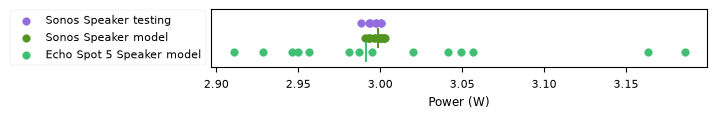

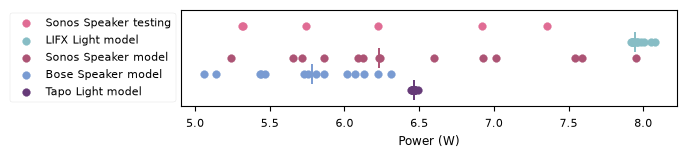

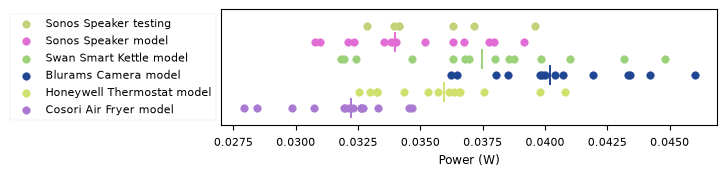

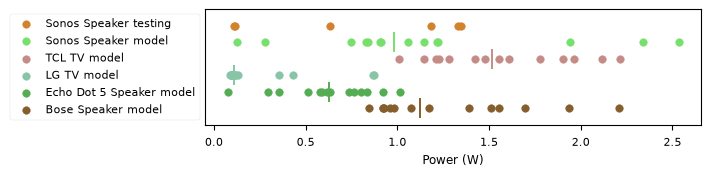

In [16]:
# | label: confused with

# for a device, see what other devices it is confused with
# [ for device, class_ in all.classes.items() if class]


# lifx = all.devices[2]
# 1 function for getting data either training or otherwise to plot.


# 1 function to actually plot it
def confused_with(exp: Experiment, name: str, state: State) -> list[Trace]:
    # return training traces that are confused with the device, and the devices training and testing traces.
    device = exp.get_device(name)
    combo = (device, state)
    selected_data = exp.get_data(*combo)[0]
    confused = list(exp.classes[combo].keys())
    traces = [exp.get_data(*c)[0].training for c in confused]
    if combo not in confused:
        traces = [selected_data.training] + traces

    # TODO: ensure device is first
    traces = [selected_data.testing] + traces
    return traces


def plot_metrics(exp: Experiment, to_plot: list[Trace], log_scale=False):
    if len(exp.metrics) > 1:
        raise ValueError

    fig, ax = plt.subplots()

    n = len(to_plot)
    for i, trace in enumerate(to_plot):
        metric = [profile[exp.metrics[0]] for profile in trace.profile]
        colour = ColorHash((trace)).hex
        ax.scatter(
            metric,
            [n - i] * len(trace.profile),
            label=f"{trace.data.device.name()} {trace.type}",
            c=colour,
        )
        if trace.type == TraceType.TRAINING:
            ax.scatter(np.median(metric), n - i, marker="|", c=colour, s=200)
    if log_scale:
        ax.set_xscale("log")

    ax.set_ylim((0, n + 1))
    ax.legend(loc="center right", bbox_to_anchor=(0, 0.5))
    ax.set_yticks([])
    fig.set_figheight(n / 4)

    ax.set_xlabel("Power (W)")


plot_metrics(summary_idle_mean, confused_with(summary_idle_mean, "sonos", State.IDLE))

plot_metrics(
    summary_active_mean, confused_with(summary_active_mean, "sonos", State.ACTIVE)
)

# TODO mode to plot overlapping distributions
# TODO randomly selected windows, are there startup effects?

std_idle = common([State.IDLE], [Metric.STD])
std_active = common([State.ACTIVE], [Metric.STD])
plot_metrics(std_idle, confused_with(std_idle, "sonos", State.IDLE))

plot_metrics(std_active, confused_with(std_active, "sonos", State.ACTIVE))
plt.show()

TypeError: unsupported operand type(s) for -: 'Data' and 'Data'

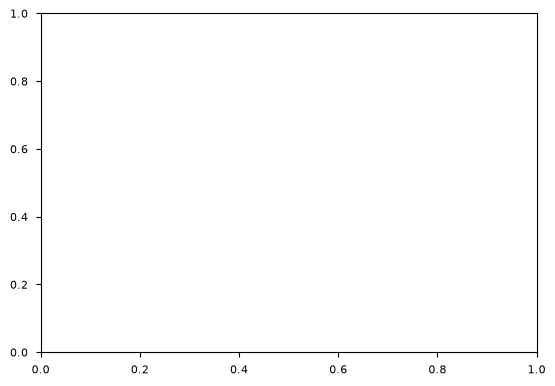

In [17]:
# | label: mu sigma

mu_sigma = Experiment(
    c,
    [State.IDLE],
    [Metric.MEAN, Metric.STD],
    Classifier.Median,
    config["w"],
    config["s"],
)

graph_confusion_matrix(mu_sigma)
print(mu_sigma.f1_macro_average)

mu_sigma = Experiment(
    c,
    [State.ACTIVE],
    [Metric.MEAN, Metric.STD],
    Classifier.Median,
    config["w"],
    config["s"],
)

graph_confusion_matrix(mu_sigma)
print(mu_sigma.f1_macro_average)

State,Macro Average F1 score,Devices with Precision > 90%
Idle,0.717,19 / 32
Average,0.857,21 / 32


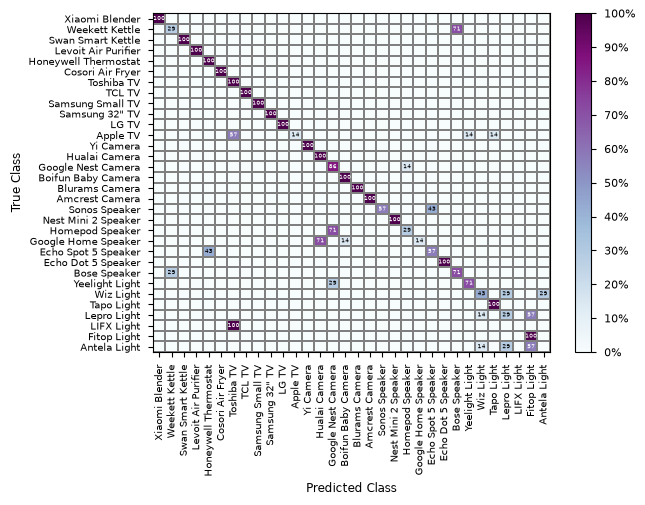

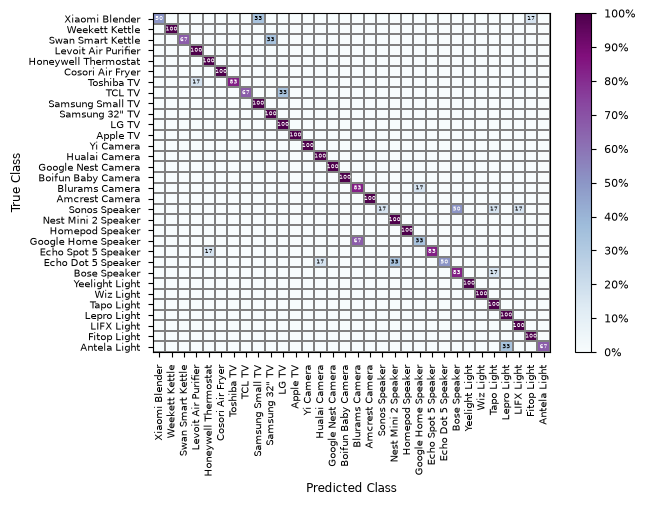

In [ ]:
# | label: confusion matrix
idle = Experiment(
    c,
    [State.IDLE],
    [Metric.MEAN],
    Classifier.Median,
    config["w"],
    config["s"],
)
graph_confusion_matrix(idle)

active = Experiment(
    c,
    [State.ACTIVE],
    [Metric.MEAN],
    Classifier.Median,
    config["w"],
    config["s"],
)
graph_confusion_matrix(active)
mean = pd.DataFrame(
    data={
        "Macro Average F1 score": [idle.f1_macro_average, active.f1_macro_average],
        "Devices with Precision > 90%": [
            f"{len([score for score in idle.precision.values() if score >= 0.9])} / {len(idle.devices)}",
            f"{len([score for score in active.precision.values() if score >= 0.9])} / {len(active.devices)}",
        ],
    },
    index=["Idle", "Average"],
)
mean.columns.name = "State"
typst_table(
    mean.style.format(precision=3),
    "mean",
)
plt.show()

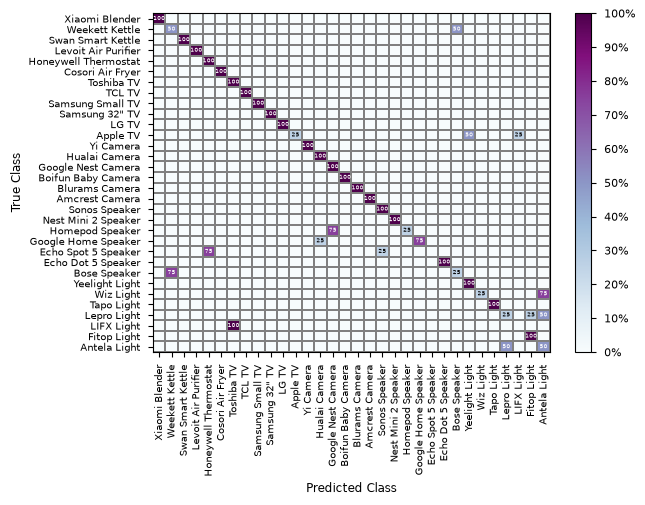

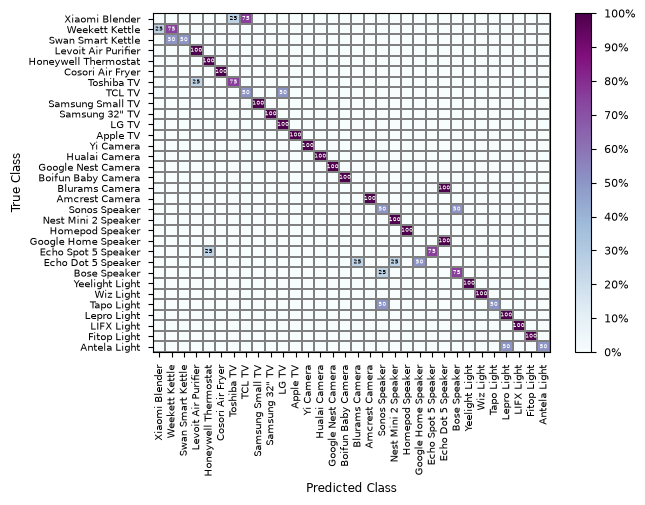

In [ ]:
# | label: fft

fft = Experiment(
    c,
    [State.IDLE],
    [Metric.FFT],
    Classifier.Median,
    300,
    120,
)

graph_confusion_matrix(fft)

fft_both = Experiment(
    c,
    [State.ACTIVE],
    [Metric.MEAN, Metric.FFT],
    Classifier.Median,
    300,
    120,
)

graph_confusion_matrix(fft_both)

In [39]:
# | label: combined

both = Experiment(
    c,
    states=[State.IDLE, State.ACTIVE],
    metrics=[Metric.MEAN],
    classify_by=Classifier.Median,
    w=config["w"],
    s=config["s"],
)

# both.f1_macro_average

both_mu_sigma = Experiment(
    c,
    states=[State.IDLE, State.ACTIVE],
    metrics=[Metric.MEAN, Metric.STD],
    classify_by=Classifier.Median,
    w=config["w"],
    s=config["s"],
)

# both_mu_sigma.f1_macro_average

# accuracy at picking state, assumes only 2 states

state = {state: [0.0, 0.0] for state in State}
for (_, real_state), counter in both.classes.items():
    total = 0
    for (_, predicted_state), count in counter.items():
        if predicted_state == real_state:
            total += count

    state[real_state][0] += total / counter.total() / len(both.devices)

for (_, real_state), counter in both_mu_sigma.classes.items():
    total = 0
    for (_, predicted_state), count in counter.items():
        if predicted_state == real_state:
            total += count

    state[real_state][1] += total / counter.total() / len(both.devices)
    # distributive
both = pd.DataFrame(
    data=state, index=[f"{mean_fancy}", f"{mean_fancy} and {std_fancy}"]
)
both.columns = both.columns.str.capitalize()
typst_table(
    both.style.format(precision=3),
    "both",
)

# graph_confusion_matrix(both)

,Active,Idle
μ,0.859,0.937
μ and σ,0.911,0.990


IndexError: list index out of range

In [53]:
# | label: my dataset
import csv
import os

# figure out how much data there is
BASE_PATH = "../data"
mydata = Context(BASE_PATH, categories=False)
# Experiment(mydata, states=[State.IDLE])
files = {device: os.listdir(f"{BASE_PATH}/{device}") for device in mydata.devices}


def get_file_length(filename):
    df = pd.read_csv(filename)
    # print(filename, len(df.index))
    return len(df.index)


# get_file_length("./data/GoogleNestHub/2026-10-26T16:20:56.474563.csv")
lengths = {
    device: [get_file_length(f"{BASE_PATH}/{device}/{file}") for file in files]
    for device, files in files.items()
}

data_stats = pd.DataFrame(
    data={
        "Files": [len(files[device]) for device in mydata.devices],
        "Total Length (hours)": [
            sum(lengths[device]) / 60 / 60 for device in mydata.devices
        ],
    },
    index=mydata.devices,
)

# printdata_stats.agg(sum).to_frame("Total")
bold = lambda x: "font-weight: bold"

typst_table(
    data_stats.style.format(precision=0).concat(
        data_stats.agg(sum)
        .to_frame("Total")
        .transpose()
        .style.format(precision=0)
        .map_index(bold)
        .map(bold)
    ),
    "mydata",
)

,Files,Total Length (hours)
GoogleNestHub,127,142
EZVIZ,17,78
GoogleHome,18,103
AppleHomePod,150,142
Aotec,149,142
AmazonEchoShow5,154,142
Total,615,749


FileNotFoundError: [Errno 2] No such file or directory: '\ntable {\n    border: none;\n    border-collapse: collapse;\n    border-spacing: 0;\n    color: black;\n    font-size: 15px;\n    table-layout: auto;\n    /* width: 100%; */\n    margin-left: auto;\n    margin-right: auto;\n}\nthead {\n    border-bottom: 1px solid black;\n    vertical-align: bottom;\n}\ntr, th, td {\n    text-align: right;\n    vertical-align: middle;\n    padding: 0.2em 0.2em;\n    line-height: normal;\n    white-space: normal;\n    max-width: none;\n    border: none;\n    font-weight: normal;\n}\ntr:nth-last-child(1) th {\n    font-weight: bold;\n}\ntbody tr:nth-child(odd) {\n    background: #f5f5f5;\n}\ntbody tr:hover {\n    background: rgba(66, 165, 245, 0.2);\n}\n\n.row_heading, .index_name {  \n  /* your stuff here */\n  text-align: left;\n}\nbody {\n    margin: 0\n    /* width:  */\n}\n\n@page {\n    size: auto;\n    margin: 0\n}'

None 0.7172155579198923 0.0
0 0.7172155579198923 0.0


TypeError: Dimensions of C (33, 33) are incompatible with X (32) and/or Y (32); see help(pcolormesh)

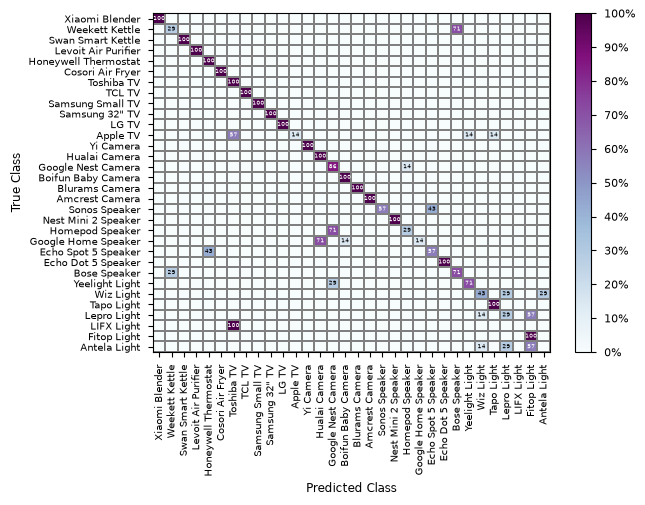

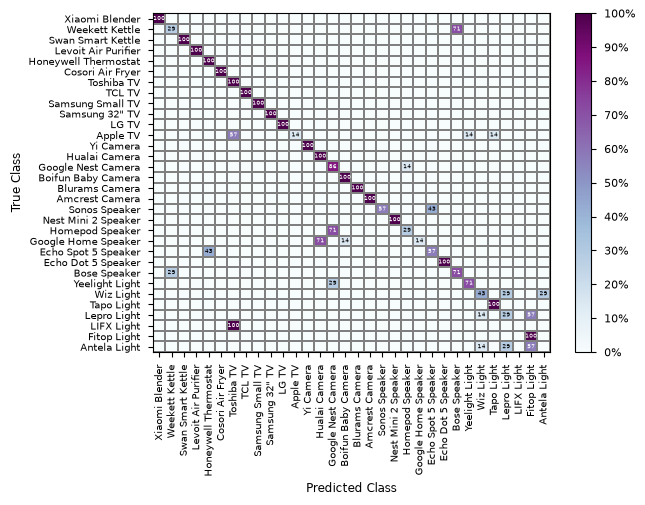

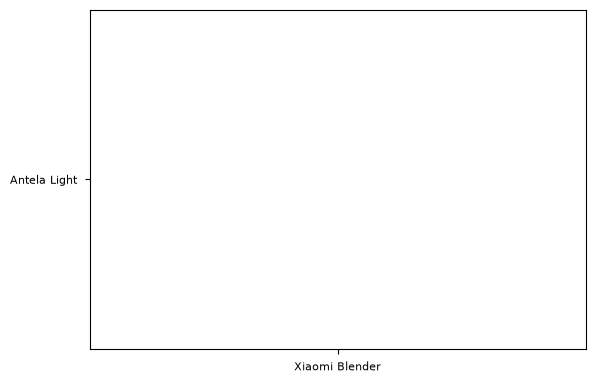

In [ ]:
%autoreload 2

c = Context("../PowerIDS/classifier/power_csv")
for threshold in [None, 0, 1, 2, 3, 4]:
    exp = Experiment(
        c,
        [State.IDLE],
        [Metric.MEAN],
        Classifier.Median,
        config['w'],
        config['s'],
        threshold=threshold,
        # include=["appletv", "samsungtv", "cosori"],
    )
    graph_confusion_matrix(exp)
    print(threshold, exp.f1_macro_average, np.mean(list(exp.unknown.values())))
# print(exp.classes)
# print(len(exp.devices), len(exp.data))
# # nice_names = [print(data) for data in exp.data]
# print(exp.data)
# # display(
# #     pd.DataFrame(
# #         data=exp.confusion_matrix, columns=nice_names
# #     ).style  # .format(precision=2)
# # )
# print(exp.f1_scores)

# TODO version of f1 including and excluding unknowns